In [5]:
import torch
import tensorflow as tf
import tensorflow_datasets as tfds

print(torch.__version__)
print(tf.__version__)

2.13.0
2.21.0


In [6]:
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from sklearn.metrics import confusion_matrix
import pandas as pd

In [7]:
from pathlib import Path

In [8]:
DATA_DIR = Path("/Users/vishnuparthasarathy/Downloads/VMMRdb")

print(list(DATA_DIR.iterdir())[:10])

[PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/toyota_corolla_wagon_1996'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/buick_regal_1993'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mazda_mpv_1997'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/ford_tempo_1988'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/hyundai_sonata_2014'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/nissan_rogue_2010'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/pontiac_montana_2005'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/bmw_x3_2008'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/toyota_tundra_2014')]


In [9]:
image_paths = list(DATA_DIR.rglob("*.jpg"))

print("Number of images:", len(image_paths))
print(image_paths[:5])

Number of images: 281752
[PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_7.jpg'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_6.jpg'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_4.jpg'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_5.jpg'), PosixPath('/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_1.jpg')]


In [10]:
for path in image_paths[:5]:
    print(path.parent.name)

mercedes benz_e430_1999
mercedes benz_e430_1999
mercedes benz_e430_1999
mercedes benz_e430_1999
mercedes benz_e430_1999


In [11]:
data = []

for path in image_paths:
    label = path.parent.name
    
    data.append({
        "image": str(path),
        "label": label
    })

df = pd.DataFrame(data)

df.head()

,image,label
0,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999
1,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999
2,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999
3,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999
4,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999


In [12]:
df.shape

(281752, 2)

In [13]:
def parse_label(label):
    parts = label.split("_")
    
    year = parts[-1]
    model = parts[-2]
    make = " ".join(parts[:-2])
    
    return make, model, year

In [14]:
data = []

for path in image_paths:
    label = path.parent.name
    make, model, year = parse_label(label)
    
    data.append({
        "image": str(path),
        "label": label,
        "make": make,
        "model": model,
        "year": year
    })

df = pd.DataFrame(data)

In [15]:
df.shape

(281752, 5)

In [16]:
df.head()

,image,label,make,model,year
0,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999,mercedes benz,e430,1999
1,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999,mercedes benz,e430,1999
2,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999,mercedes benz,e430,1999
3,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999,mercedes benz,e430,1999
4,/Users/vishnuparthasarathy/Downloads/VMMRdb/me...,mercedes benz_e430_1999,mercedes benz,e430,1999


In [17]:
print("Images:", len(df))
print("Classes:", df["label"].nunique())
print("Makes:", df["make"].nunique())
print("Models:", df["model"].nunique())

print("\nImages per class:")
print(df["label"].value_counts().describe())

Images: 281752
Classes: 9166
Makes: 145
Models: 1071

Images per class:
count    9166.000000
mean       30.738817
std        57.865030
min         1.000000
25%         3.000000
50%         9.000000
75%        30.000000
max       883.000000
Name: count, dtype: float64


In [18]:
counts = df["label"].value_counts()

print("Classes with 1 image:", (counts == 1).sum())
print("Classes with <= 3 images:", (counts <= 3).sum())
print("Classes with <= 5 images:", (counts <= 5).sum())
print("Classes with <= 10 images:", (counts <= 10).sum())
print("Classes with >= 50 images:", (counts >= 50).sum())
print("Classes with >= 100 images:", (counts >= 100).sum())

counts.sort_values(ascending=False).head(30)

Classes with 1 image: 1190
Classes with <= 3 images: 2526
Classes with <= 5 images: 3511
Classes with <= 10 images: 4890
Classes with >= 50 images: 1575
Classes with >= 100 images: 718


label
ford_explorer_2002          883
nissan_altima_2005          716
ford_explorer_2003          582
honda_civic_2002            535
ford_explorer_2004          526
ford_mustang_2000           504
chevrolet_silverado_2004    487
toyota_camry_2007           467
nissan_altima_2002          458
dodge_grand caravan_2005    447
honda_civic_1998            443
honda_accord_2000           438
nissan_altima_2003          438
honda_accord_1999           437
honda_civic_2001            434
chevrolet_impala_2006       431
honda_accord_1998           429
honda_accord_2003           420
nissan_altima_2006          419
ford_f150_2004              414
ford_taurus_2001            410
honda_accord_2005           409
nissan_altima_2008          408
ford_taurus_2003            405
volkswagen_jetta_2006       402
nissan_maxima_2000          398
toyota_camry_2002           396
ford_expedition_2003        394
jeep_grand_cherokee_2004    390
honda_civic_2000            388
Name: count, dtype: int64

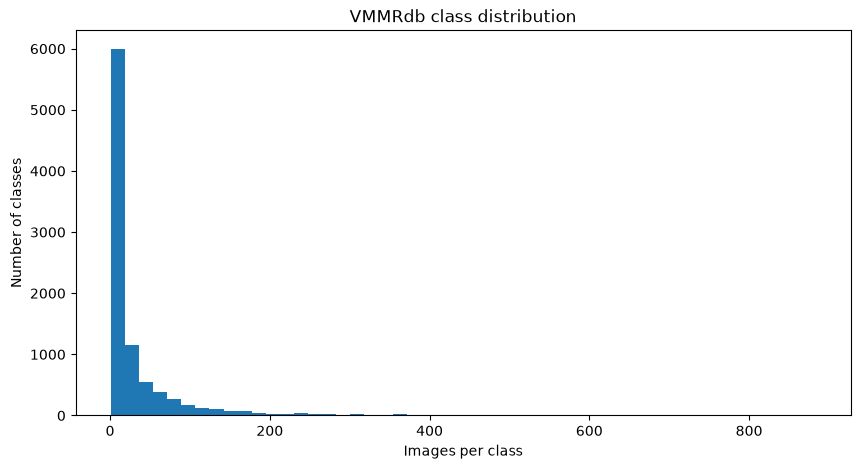

In [19]:
plt.figure(figsize=(10, 5))
plt.hist(counts, bins=50)
plt.xlabel("Images per class")
plt.ylabel("Number of classes")
plt.title("VMMRdb class distribution")
plt.show()

In [20]:
counts = df["label"].value_counts()

for n in [5, 10, 20, 30, 50, 100]:
    print(
        f">= {n:3} images: "
        f"{(counts >= n).sum():4} classes, "
        f"{counts[counts >= n].sum():7,} images"
    )

>=   5 images: 6097 classes, 275,102 images
>=  10 images: 4481 classes, 264,278 images
>=  20 images: 3053 classes, 244,524 images
>=  30 images: 2316 classes, 226,877 images
>=  50 images: 1575 classes, 198,186 images
>= 100 images:  718 classes, 137,867 images


In [21]:
MODEL_PATH = Path("/Users/vishnuparthasarathy/Downloads/dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth")

print(MODEL_PATH.exists())

True


In [23]:
# git clone https://github.com/facebookresearch/dinov3.git ..

fatal: destination path 'dinov3' already exists and is not an empty directory.


In [26]:
REPO_DIR = Path("../dinov3")
MODEL_PATH = Path.home() / "Downloads" / "dinov3_vitl16_pretrain_lvd1689m-8aa4cbdd.pth"

print(REPO_DIR.exists())
print(MODEL_PATH.exists())

True
True


In [27]:
import torch

model = torch.hub.load(
    str(REPO_DIR),
    "dinov3_vitl16",
    source="local",
    weights=str(MODEL_PATH)
)

In [28]:
print(type(model))
print(sum(p.numel() for p in model.parameters()) / 1e6, "million parameters")

<class 'dinov3.models.vision_transformer.DinoVisionTransformer'>
303.154176 million parameters


In [29]:
print("MPS available:", torch.backends.mps.is_available())

MPS available: True


In [30]:
device = torch.device("mps")
model = model.to(device)
model.eval()

DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (rope_embed): RopePositionEmbedding()
  (blocks): ModuleList(
    (0-23): 24 x SelfAttentionBlock(
      (norm1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): SelfAttention(
        (qkv): LinearKMaskedBias(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (norm2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScal

In [32]:
img_path = df.iloc[0]["image"]
print(img_path)

/Users/vishnuparthasarathy/Downloads/VMMRdb/mercedes benz_e430_1999/mercedes_e430_1999_7.jpg


In [33]:
from PIL import Image
from torchvision.transforms import v2

In [34]:
img_path = df.iloc[0]["image"]
image = Image.open(img_path).convert("RGB")

print(image.size)

(548, 376)


In [35]:
transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((256, 256), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

x = transform(image).unsqueeze(0)

print(x.shape)

torch.Size([1, 3, 256, 256])


In [170]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = model.to(device)
model.eval()

x = x.to(device)

In [171]:
with torch.inference_mode():
    features = model(x)

print(features.shape)

torch.Size([1, 1024])


In [37]:
from tqdm.auto import tqdm

In [174]:
# Use GPU if available
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = model.to(device)
model.eval()

# Take 1,000 images
sample_df = df.sample(n=1000, random_state=42).reset_index(drop=True)

# Storage
embeddings = []
labels = []
paths = []

batch_size = 16

for start in tqdm(range(0, len(sample_df), batch_size)):
    batch_df = sample_df.iloc[start:start + batch_size]

    images = []

    for path in batch_df["image"]:
        image = Image.open(path).convert("RGB")
        images.append(transform(image))

    x = torch.stack(images).to(device)

    # DINOv3 inference
    with torch.inference_mode():
        features = model(x)

    embeddings.append(features.cpu().numpy())
    labels.extend(batch_df["label"].tolist())
    paths.extend(batch_df["image"].tolist())

# Combine batches
embeddings = np.concatenate(embeddings, axis=0)

print("Embeddings:", embeddings.shape)
print("Labels:", len(labels))
print("Images:", len(paths))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 63/63 [00:33<00:00,  1.90it/s]

Embeddings: (1000, 1024)
Labels: 1000
Images: 1000


In [175]:
np.savez(
    "../data/dinov3_vmmrdb_1000.npz",
    embeddings=embeddings,
    labels=np.array(labels),
    paths=np.array(paths)
)

print("Saved!")

Saved!


In [176]:
from sklearn.metrics.pairwise import cosine_similarity

# Similarity of image 0 to every other image
similarities = cosine_similarity(
    embeddings[0:1],
    embeddings
)[0]

# Don't return itself
similarities[0] = -1

top_indices = np.argsort(similarities)[-10:][::-1]

for i in top_indices:
    print(f"{similarities[i]:.4f}  {labels[i]}")

0.5941  ford_escape_2003
0.5858  mercury_mariner_2008
0.5769  ford_escape_2011
0.5583  ford_escape_2012
0.5498  chevrolet_trailblazer_2004
0.5267  chevrolet_equinox_2007
0.5265  chevrolet_trailblazer_2004
0.5246  honda_pilot_2011
0.5218  kia_sedona_2007
0.5108  jeep_grand_cherokee_2004


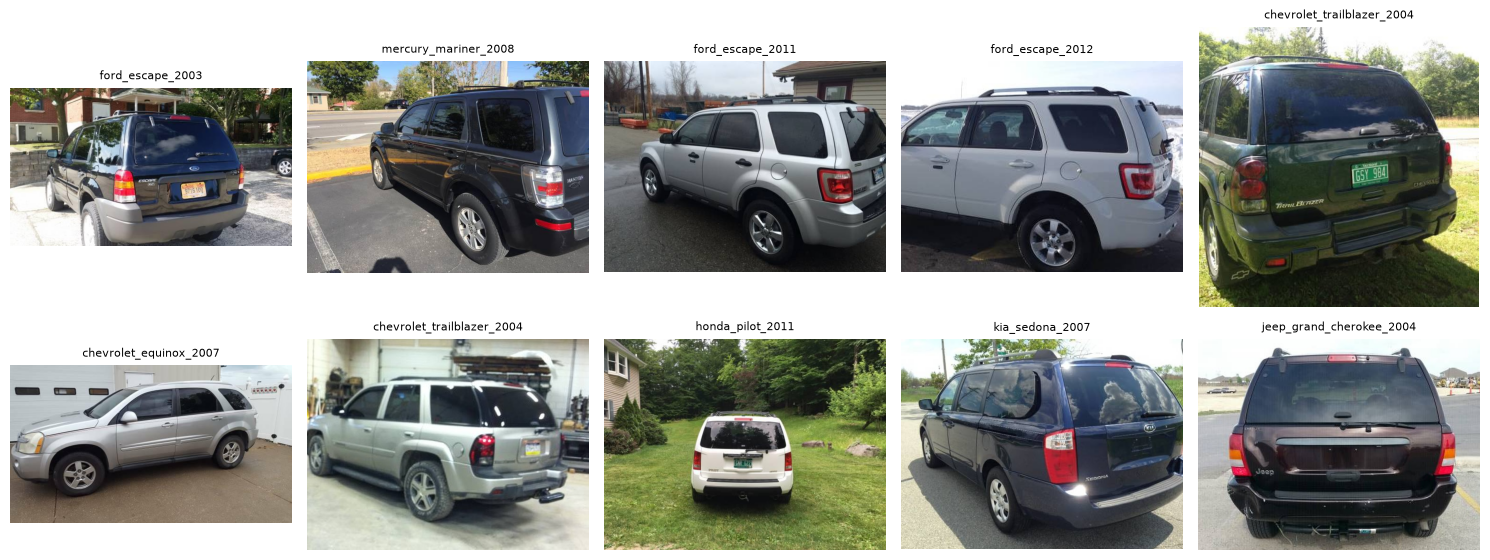

In [177]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, i in zip(axes.flat, top_indices):
    image = Image.open(paths[i]).convert("RGB")
    ax.imshow(image)
    ax.set_title(labels[i], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [178]:
similarities = cosine_similarity(embeddings)

# Ignore self-similarity
np.fill_diagonal(similarities, -1)

nearest = similarities.argmax(axis=1)

same_label = np.array(labels) == np.array(labels)[nearest]

print("Nearest-neighbor accuracy:", same_label.mean())

Nearest-neighbor accuracy: 0.099


In [179]:
from collections import Counter
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

labels_arr = np.array(labels)

# How many times does each class occur in our 1000-image sample?
counts = Counter(labels_arr)

print("Images:", len(labels_arr))
print("Unique classes:", len(counts))
print("Classes with >=2 images:", sum(v >= 2 for v in counts.values()))
print("Classes with >=3 images:", sum(v >= 3 for v in counts.values()))

Images: 1000
Unique classes: 813
Classes with >=2 images: 146
Classes with >=3 images: 29


In [180]:
similarities = cosine_similarity(embeddings)
np.fill_diagonal(similarities, -1)

nearest = similarities.argmax(axis=1)

# Only evaluate images whose class appears at least twice
valid = np.array([counts[label] >= 2 for label in labels_arr])

same_label = labels_arr == labels_arr[nearest]

print("Overall NN accuracy:", same_label.mean())
print("NN accuracy among classes with >=2 images:", same_label[valid].mean())

Overall NN accuracy: 0.099
NN accuracy among classes with >=2 images: 0.2972972972972973


In [181]:
def get_make_model(label):
    parts = label.rsplit("_", 1)
    return parts[0]

make_model = np.array([get_make_model(x) for x in labels_arr])

same_make_model = make_model == make_model[nearest]

print("Exact make + model NN accuracy:", same_make_model.mean())

Exact make + model NN accuracy: 0.483


In [182]:
def get_make(label):
    return label.split("_")[0]

make = np.array([get_make(x) for x in labels_arr])

same_make = make == make[nearest]

print("Make-only NN accuracy:", same_make.mean())

Make-only NN accuracy: 0.696


In [183]:
import numpy as np

labels_arr = np.array(labels)

def get_make(label):
    return label.split("_")[0]

makes = np.array([get_make(label) for label in labels_arr])

print(makes[:10])

['chevrolet' 'toyota' 'chevrolet' 'chevrolet' 'oldsmobile' 'volkswagen'
 'ford' 'acura' 'mercury' 'chevrolet']


In [184]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

embeddings_2d = pca.fit_transform(embeddings)

print(embeddings_2d.shape)
print("Variance explained:", pca.explained_variance_ratio_.sum())

(1000, 2)
Variance explained: 0.1448238


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

make_counts = Counter(makes)
top_makes = [make for make, count in make_counts.most_common(10)]

plt.figure(figsize=(12, 8))

for make in top_makes:
    mask = makes == make
    plt.scatter(
        embeddings_2d[mask, 0],
        embeddings_2d[mask, 1],
        label=make,
        alpha=0.7
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DINOv3 VMMRdb Embeddings — Top 10 Makes")
plt.legend()
plt.show()

In [187]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

embeddings_umap = reducer.fit_transform(embeddings)

print(embeddings_umap.shape)

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(1000, 2)


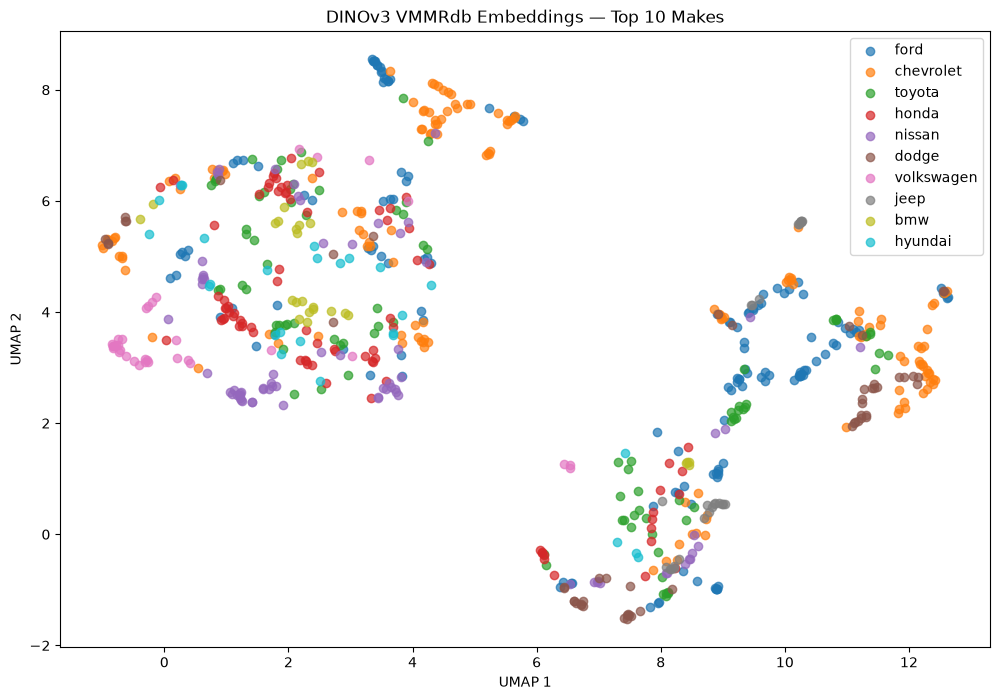

In [188]:
plt.figure(figsize=(12, 8))

for make in top_makes:
    mask = makes == make
    
    plt.scatter(
        embeddings_umap[mask, 0],
        embeddings_umap[mask, 1],
        label=make,
        alpha=0.7
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("DINOv3 VMMRdb Embeddings — Top 10 Makes")
plt.legend()
plt.show()

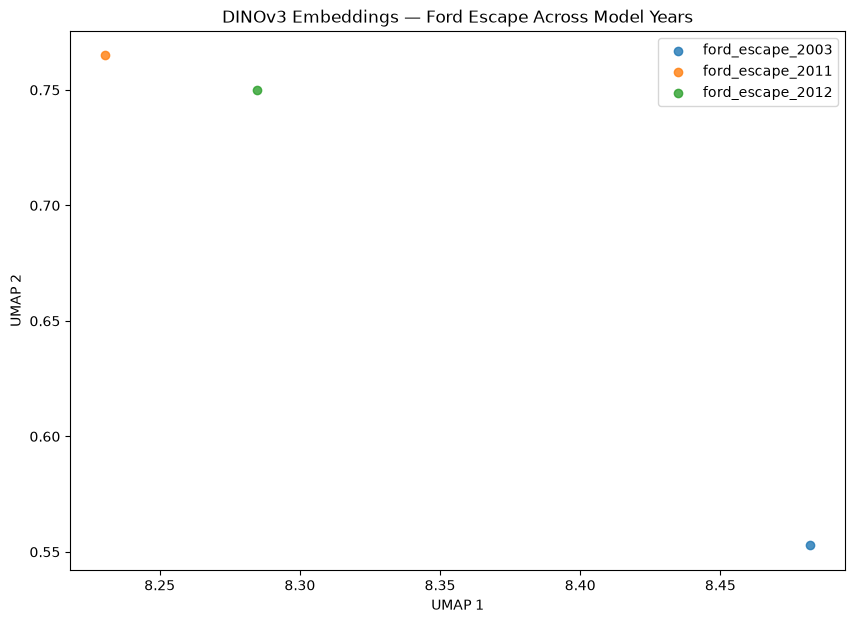

In [189]:
import matplotlib.pyplot as plt
import numpy as np

target_classes = [
    "ford_escape_2003",
    "ford_escape_2011",
    "ford_escape_2012"
]

plt.figure(figsize=(10, 7))

for label in target_classes:
    mask = labels_arr == label
    
    plt.scatter(
        embeddings_umap[mask, 0],
        embeddings_umap[mask, 1],
        label=label,
        alpha=0.8
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("DINOv3 Embeddings — Ford Escape Across Model Years")
plt.legend()
plt.show()

In [190]:
N = 10_000

sample_df = df.sample(
    n=N,
    random_state=42
).reset_index(drop=True)

print(len(sample_df))

10000


In [191]:
# Use GPU if available
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = model.to(device)
model.eval()

# Take 1,000 images
sample_df = df.sample(n=10000, random_state=42).reset_index(drop=True)

# Storage
embeddings = []
labels = []
paths = []

batch_size = 16

for start in tqdm(range(0, len(sample_df), batch_size)):
    batch_df = sample_df.iloc[start:start + batch_size]

    images = []

    for path in batch_df["image"]:
        image = Image.open(path).convert("RGB")
        images.append(transform(image))

    x = torch.stack(images).to(device)

    # DINOv3 inference
    with torch.inference_mode():
        features = model(x)

    embeddings.append(features.cpu().numpy())
    labels.extend(batch_df["label"].tolist())
    paths.extend(batch_df["image"].tolist())

# Combine batches
embeddings = np.concatenate(embeddings, axis=0)

print("Embeddings:", embeddings.shape)
print("Labels:", len(labels))
print("Images:", len(paths))

100%|███████████████████████████████████████████████████████████████████████████████████████████████| 625/625 [05:36<00:00,  1.86it/s]

Embeddings: (10000, 1024)
Labels: 10000
Images: 10000


In [192]:
np.savez(
    "../data/dinov3_vmmrdb_10000.npz",
    embeddings=embeddings,
    labels=np.array(labels),
    paths=np.array(paths)
)

print("Saved!")

Saved!


In [193]:
from sklearn.metrics.pairwise import cosine_similarity

# Similarity of image 0 to every other image
similarities = cosine_similarity(
    embeddings[0:1],
    embeddings
)[0]

# Don't return itself
similarities[0] = -1

top_indices = np.argsort(similarities)[-10:][::-1]

for i in top_indices:
    print(f"{similarities[i]:.4f}  {labels[i]}")

0.7601  chevrolet_equinox_2005
0.7523  chevrolet_equinox_2008
0.7492  chevrolet_equinox_2007
0.7479  chevrolet_equinox_2008
0.6513  chevrolet_equinox_2006
0.6383  jeep_grand_cherokee_2006
0.6266  mercedes benz_gl450_2007
0.6224  chevrolet_equinox_2006
0.6185  pontiac_torrent_2008
0.6126  chevrolet_equinox_2011


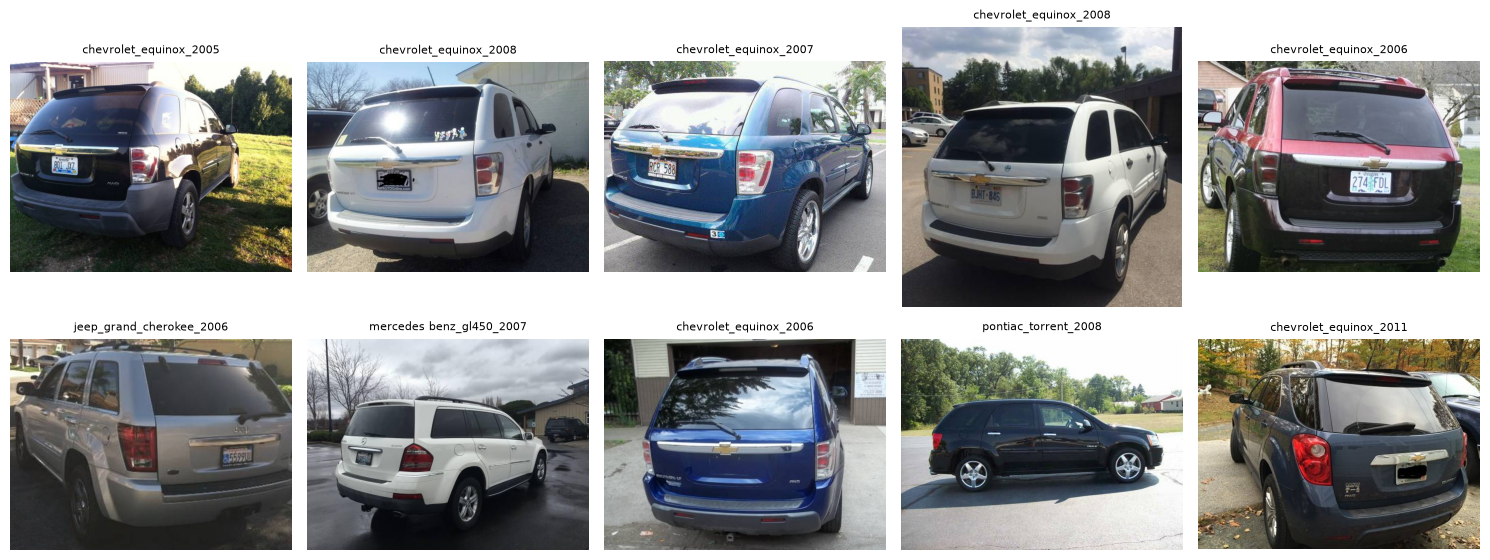

In [194]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, i in zip(axes.flat, top_indices):
    image = Image.open(paths[i]).convert("RGB")
    ax.imshow(image)
    ax.set_title(labels[i], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
similarities = cosine_similarity(embeddings)

# Ignore self-similarity
np.fill_diagonal(similarities, -1)

nearest = similarities.argmax(axis=1)

same_label = np.array(labels) == np.array(labels)[nearest]

print("Nearest-neighbor accuracy:", same_label.mean())

In [196]:
from collections import Counter
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

labels_arr = np.array(labels)

# How many times does each class occur in our 1000-image sample?
counts = Counter(labels_arr)

print("Images:", len(labels_arr))
print("Unique classes:", len(counts))
print("Classes with >=2 images:", sum(v >= 2 for v in counts.values()))
print("Classes with >=3 images:", sum(v >= 3 for v in counts.values()))

Images: 10000
Unique classes: 3628
Classes with >=2 images: 1903
Classes with >=3 images: 1170


In [197]:
make_model = np.array([get_make_model(x) for x in labels_arr])

same_make_model = make_model == make_model[nearest]

print("Exact make + model NN accuracy:", same_make_model.mean())

make = np.array([get_make(x) for x in labels_arr])

same_make = make == make[nearest]

print("Make-only NN accuracy:", same_make.mean())

Exact make + model NN accuracy: 0.776
Make-only NN accuracy: 0.9236


In [198]:
# Use GPU if available
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = model.to(device)
model.eval()

# Take 1,000 images
sample_df = df.sample(n=281752, random_state=42).reset_index(drop=True)

# Storage
embeddings = []
labels = []
paths = []

batch_size = 16

for start in tqdm(range(0, len(sample_df), batch_size)):
    batch_df = sample_df.iloc[start:start + batch_size]

    images = []

    for path in batch_df["image"]:
        image = Image.open(path).convert("RGB")
        images.append(transform(image))

    x = torch.stack(images).to(device)

    # DINOv3 inference
    with torch.inference_mode():
        features = model(x)

    embeddings.append(features.cpu().numpy())
    labels.extend(batch_df["label"].tolist())
    paths.extend(batch_df["image"].tolist())

# Combine batches
embeddings = np.concatenate(embeddings, axis=0)

print("Embeddings:", embeddings.shape)
print("Labels:", len(labels))
print("Images:", len(paths))

100%|█████████████████████████████████████████████████████████████████████████████████████████| 17610/17610 [2:42:24<00:00,  1.81it/s]

Embeddings: (281752, 1024)
Labels: 281752
Images: 281752


In [ ]:
np.savez(
    "../data/dinov3_vmmrdb_full.npz",
    embeddings=embeddings,
    labels=np.array(labels),
    paths=np.array(paths)
)

print("Saved!")

In [44]:
data = np.load("../data/dinov3_vmmrdb_full.npz", allow_pickle=True)

embeddings = data["embeddings"]
labels = data["labels"]
paths = data["paths"]

print(embeddings.shape)
print(len(labels))

(281752, 1024)
281752


In [43]:
print(data.files)

['embeddings', 'labels', 'paths']


In [40]:
from sklearn.metrics.pairwise import cosine_similarity

# Similarity of image 0 to every other image
similarities = cosine_similarity(
    embeddings[0:1],
    embeddings
)[0]

# Don't return itself
similarities[0] = -1

top_indices = np.argsort(similarities)[-10:][::-1]

for i in top_indices:
    print(f"{similarities[i]:.4f}  {labels[i]}")

0.8163  chevrolet_equinox_2005
0.8024  chevrolet_equinox_2007
0.7957  chevrolet_equinox_2005
0.7833  chevrolet_equinox_2007
0.7806  chevrolet_equinox_2005
0.7802  chevrolet_equinox_2006
0.7785  chevrolet_equinox_2006
0.7782  chevrolet_equinox_2006
0.7757  chevrolet_equinox_2005
0.7707  chevrolet_equinox_2006


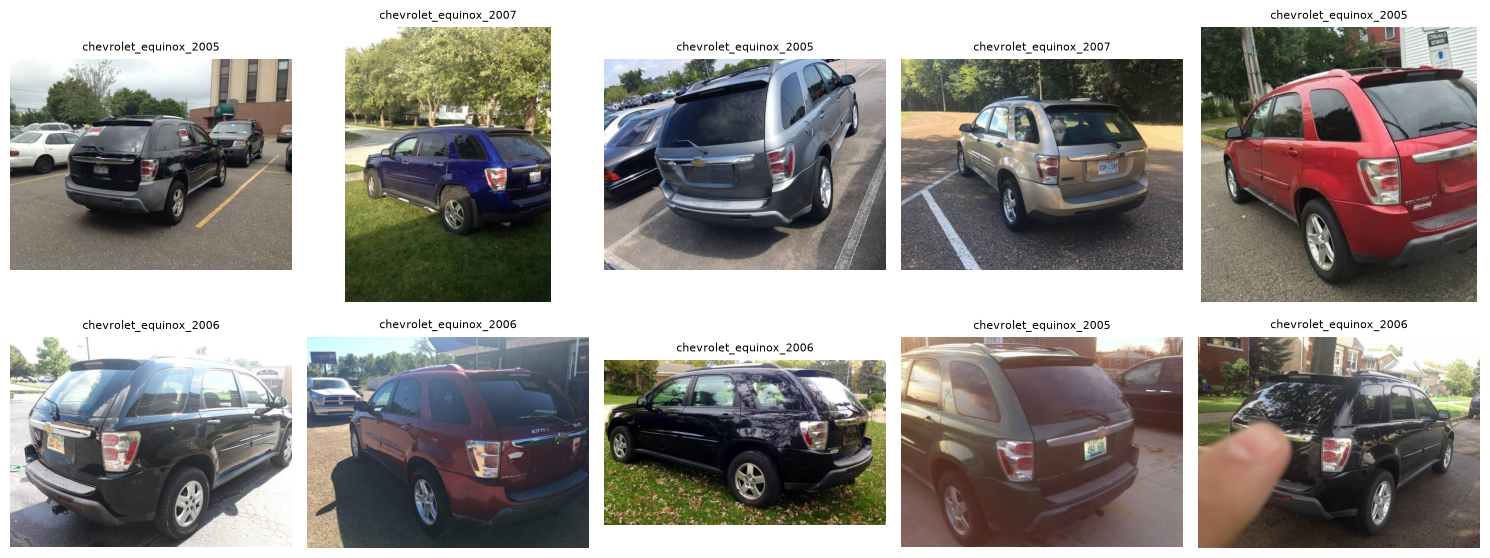

In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, i in zip(axes.flat, top_indices):
    image = Image.open(paths[i]).convert("RGB")
    ax.imshow(image)
    ax.set_title(labels[i], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
similarities = cosine_similarity(embeddings)

# Ignore self-similarity
np.fill_diagonal(similarities, -1)

nearest = similarities.argmax(axis=1)

same_label = np.array(labels) == np.array(labels)[nearest]

print("Nearest-neighbor accuracy:", same_label.mean())

In [ ]:
from collections import Counter
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

labels_arr = np.array(labels)

# How many times does each class occur in our 1000-image sample?
counts = Counter(labels_arr)

print("Images:", len(labels_arr))
print("Unique classes:", len(counts))
print("Classes with >=2 images:", sum(v >= 2 for v in counts.values()))
print("Classes with >=3 images:", sum(v >= 3 for v in counts.values()))

In [ ]:
make_model = np.array([get_make_model(x) for x in labels_arr])

same_make_model = make_model == make_model[nearest]

print("Exact make + model NN accuracy:", same_make_model.mean())

make = np.array([get_make(x) for x in labels_arr])

same_make = make == make[nearest]

print("Make-only NN accuracy:", same_make.mean())